<a href="https://colab.research.google.com/github/JaCaRego/JaCaRego/blob/main/Profissao_Cientista_de_Dados_M14_Pratique_Jales2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MÓDULO 14 - Exercício**
# Pré Processamento dos Dados - A primeira etapa Pré Modelagem

Para nossa atividade usaremos uma base de churn também, porém essa base não diz respeito a serviços bancários e sim serviços de internet, telefone e tv - Telecomunicação.

Vamos realizar aqui as etapas de limpeza e tratamento de dados vistos durante a aula, porém aplicados a essa base nova.

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

In [4]:
#Lembrem-se sempre de alterar a importação dos dados de acordo com o diretório de vocês.
df = pd.read_csv("CHURN_TELECON_MOD08_TAREFA.csv", delimiter=';')

df.head(10)

,customerID,Genero,Idoso,Casado,Dependents,Tempo_como_Cliente,PhoneService,Servico_Internet,Servico_Seguranca,Suporte_Tecnico,StreamingTV,Tipo_Contrato,PaymentMethod,Pagamento_Mensal,Total_Pago,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,DSL,No,No,No,Month-to-month,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,DSL,Yes,No,No,One year,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,DSL,Yes,No,No,Month-to-month,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,DSL,Yes,Yes,No,One year,Bank transfer (automatic),NaN,1840.75,No
4,9237-HQITU,NaN,0,No,No,2,Yes,Fiber optic,No,No,No,Month-to-month,Electronic check,NaN,151.65,Yes
5,9305-CDSKC,NaN,0,No,No,8,Yes,Fiber optic,No,No,Yes,Month-to-month,Electronic check,NaN,820.50,NaN
6,1452-KIOVK,NaN,0,No,Yes,22,Yes,Fiber optic,No,No,Yes,Month-to-month,Credit card (automatic),NaN,1949.40,NaN
7,6713-OKOMC,NaN,0,No,No,10,No,DSL,Yes,No,No,Month-to-month,Mailed check,NaN,301.90,NaN
8,7892-POOKP,NaN,0,Yes,No,28,Yes,Fiber optic,No,Yes,Yes,Month-to-month,Electronic check,NaN,3046.05,NaN
9,6388-TABGU,NaN,0,No,Yes,62,Yes,dsl,Yes,No,No,One year,Bank transfer (automatic),NaN,3487.95,NaN


Legenda dos dados:

*   **CustomerID** : Esse é o ID único de cada cliente nosso da rede de produtos de telecomunicação.

*   **Genero** : O genero dos nossos clientes.

*   **Idoso** : Se nosso cliente tem acima de 60 anos ou não. (Sim = 1 | Não = 0)

*   **Casado** : Se nosso cliente é casado ou não.

*   **Dependents** : Se cliente tem dependentes.

*   **Tempo_como_Cliente** : Tempo em meses que nosso cliente está com a nossa empresa.

*   **PhoneService** : Se ele contratou serviço telefônico com a nossa empresa.

*   **Servico_Internet** : Qual o tipo de serviço de internet contratado.

*   **Servico_Seguranca** : Se ele contratou serviço de segurança com a nossa empresa.

*   **Suporte_Tecnico** : Se já acionou o suporte técnico.

*   **StreamingTV** : Se ele contratou serviço de streaming para TV.

*   **Tipo_Contrato** : Qual o tipo de contrato dos nossos clientes, se era mensal, anual etc.

*   **Tipo_Contrato** : Qual o tipo de contrato dos nossos clientes, se era mensal, anual etc.

*   **PaymentMethod** : Forma de Pagamento.

*   **Pagamento_Mensal** : Quanto o cliente pagava mensalmente.

*   **Total_Pago** : Total já pago pelo cliente para nossa companhia.

*   **Churn** : Nossa coluna mais importante, se nosso cliente nos abandonou ou não.




# 1 - Carregue a base, verifique se os tipos de dados estão de acordo com cada coluna e caso não estejam realize a transformação dos tipos de dados.

In [5]:


# Carregar o DataFrame para garantir que 'df' esteja definido
df = pd.read_csv("CHURN_TELECON_MOD08_TAREFA.csv", delimiter=';')

print('Informações iniciais do DataFrame:')
display(df.info())

# Converter 'Total_Pago' para numérico, tratando erros e preenchendo NaNs
df['Total_Pago'] = pd.to_numeric(df['Total_Pago'], errors='coerce')

# Converter 'Pagamento_Mensal' para numérico, tratando erros e preenchendo NaNs
df['Pagamento_Mensal'] = pd.to_numeric(df['Pagamento_Mensal'], errors='coerce')

print('\nInformações do DataFrame após a conversão:')
display(df.info())

print('\nPrimeiras 5 linhas do DataFrame após a conversão:')
display(df.head())

Informações iniciais do DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customerID          2500 non-null   object 
 1   Genero              2488 non-null   object 
 2   Idoso               2500 non-null   int64  
 3   Casado              2500 non-null   object 
 4   Dependents          2500 non-null   object 
 5   Tempo_como_Cliente  2500 non-null   int64  
 6   PhoneService        1018 non-null   object 
 7   Servico_Internet    2500 non-null   object 
 8   Servico_Seguranca   2500 non-null   object 
 9   Suporte_Tecnico     2500 non-null   object 
 10  StreamingTV         2500 non-null   object 
 11  Tipo_Contrato       2500 non-null   object 
 12  PaymentMethod       2500 non-null   object 
 13  Pagamento_Mensal    2175 non-null   float64
 14  Total_Pago          2500 non-null   float64
 15  Churn               

None


Informações do DataFrame após a conversão:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customerID          2500 non-null   object 
 1   Genero              2488 non-null   object 
 2   Idoso               2500 non-null   int64  
 3   Casado              2500 non-null   object 
 4   Dependents          2500 non-null   object 
 5   Tempo_como_Cliente  2500 non-null   int64  
 6   PhoneService        1018 non-null   object 
 7   Servico_Internet    2500 non-null   object 
 8   Servico_Seguranca   2500 non-null   object 
 9   Suporte_Tecnico     2500 non-null   object 
 10  StreamingTV         2500 non-null   object 
 11  Tipo_Contrato       2500 non-null   object 
 12  PaymentMethod       2500 non-null   object 
 13  Pagamento_Mensal    2175 non-null   float64
 14  Total_Pago          2500 non-null   float64
 15  Churn      

None


Primeiras 5 linhas do DataFrame após a conversão:


,customerID,Genero,Idoso,Casado,Dependents,Tempo_como_Cliente,PhoneService,Servico_Internet,Servico_Seguranca,Suporte_Tecnico,StreamingTV,Tipo_Contrato,PaymentMethod,Pagamento_Mensal,Total_Pago,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,DSL,No,No,No,Month-to-month,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,DSL,Yes,No,No,One year,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,DSL,Yes,No,No,Month-to-month,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,DSL,Yes,Yes,No,One year,Bank transfer (automatic),NaN,1840.75,No
4,9237-HQITU,NaN,0,No,No,2,Yes,Fiber optic,No,No,No,Month-to-month,Electronic check,NaN,151.65,Yes


### Explicação do Passo 1: Verificação e Conversão de Tipos de Dados

Neste passo, o código carregou o arquivo CSV em um DataFrame, exibiu as informações iniciais dos tipos de dados de cada coluna e, em seguida, converteu as colunas 'Total_Pago' e 'Pagamento_Mensal' para tipos numéricos (`float64`). Valores não numéricos nessas colunas foram automaticamente substituídos por `NaN` (valores ausentes) durante a conversão. Finalmente, o código exibiu as informações atualizadas do DataFrame e as primeiras linhas para verificar as mudanças.

# 2 - Esse exercício faremos por etapas:
A) Verifique se temos colunas com dados faltantes e traga a % dos dados faltantes por coluna.

In [6]:
# Calcular a porcentagem de valores ausentes para cada coluna
missing_percentage = df.isnull().sum() / len(df) * 100

# Filtrar e exibir apenas as colunas com valores ausentes
missing_data = missing_percentage[missing_percentage > 0].sort_values(ascending=False)

print("Porcentagem de valores ausentes por coluna:")
display(missing_data)

print("\nContagem de valores ausentes por coluna:")
display(df.isnull().sum())

Porcentagem de valores ausentes por coluna:


,0
PhoneService,59.28
Pagamento_Mensal,13.00
Genero,0.48
Churn,0.20



Contagem de valores ausentes por coluna:


,0
customerID,0
Genero,12
Idoso,0
Casado,0
Dependents,0
Tempo_como_Cliente,0
PhoneService,1482
Servico_Internet,0
Servico_Seguranca,0
Suporte_Tecnico,0


B) Exclua nessa etapa as linhas das colunas com dados faltantes que você analisar que esse método é o ideal. Justifique o motivo de estar excluindo essas linhas.

In [7]:
# Excluir linhas com valores ausentes nas colunas 'Genero' e 'Churn'
# Juntamos as colunas com poucos valores ausentes para fazer a exclusão de uma vez.
df.dropna(subset=['Genero', 'Churn'], inplace=True)

print("DataFrame após a exclusão de linhas com valores ausentes em 'Genero' e 'Churn':")

# Verificar novamente a contagem de valores ausentes após a exclusão
print("\nValores ausentes restantes por coluna:")
display(df.isnull().sum())

DataFrame após a exclusão de linhas com valores ausentes em 'Genero' e 'Churn':

Valores ausentes restantes por coluna:


,0
customerID,0
Genero,0
Idoso,0
Casado,0
Dependents,0
Tempo_como_Cliente,0
PhoneService,1482
Servico_Internet,0
Servico_Seguranca,0
Suporte_Tecnico,0


### Explicação do Passo 2B: Tratamento de Valores Ausentes (Excluir Linhas)

Neste passo, o código utilizou `df.dropna(subset=['Genero', 'Churn'], inplace=True)` para excluir as linhas onde havia valores ausentes nas colunas 'Genero' ou 'Churn'. A justificativa para essa escolha é que ambas as colunas apresentavam uma porcentagem muito baixa de valores ausentes (0.48% e 0.20% respectivamente), e a remoção dessas poucas linhas não compromete a integridade ou o volume do conjunto de dados, garantindo que essas colunas importantes estejam completas.

Agora, restam apenas valores ausentes nas colunas `PhoneService` e `Pagamento_Mensal`. Podemos seguir para a sub-etapa C, que é a imputação desses valores, utilizando média, mediana ou moda?

C) Nessa etapa substitua pela média, mediana ou moda as linhas das colunas com valores faltantes que você analisou e entendeu que esse era o melhor método. Não se esqueça de justificar sua escolha.

**Dica variáveis numéricas:** Não se esqueça de verificar a distrbuição dos dados, média e mediana.

**Dica variáveis categóricas:** Caso precise substituir uma variável categórica utilize um gráfico de barras para verificar a que mais aparece e utilizar ela na substituição.
Ou você pode optar por excluir a coluna, mas justifique sua escolha.

Caso opte por substituir você pode utilizar a função fillna:
df['SUACOLUNA'].fillna("VALOR QUE SUBSTITUIRA O NULO", inplace=True)
Ela funcionará como a replace.

In [8]:
print('Distribuição da coluna PhoneService antes da imputação:')
display(df['PhoneService'].value_counts(dropna=False))

# Determinar o modo (valor mais frequente)
phone_service_mode = df['PhoneService'].mode()[0]
print(f"\nModo da coluna 'PhoneService': {phone_service_mode}")

# Imputar valores ausentes com o modo
df['PhoneService'].fillna(phone_service_mode, inplace=True)

print('\nDistribuição da coluna PhoneService após a imputação:')
display(df['PhoneService'].value_counts(dropna=False))

Distribuição da coluna PhoneService antes da imputação:


,count
PhoneService,
NaN,1482
Yes,920
No,86



Modo da coluna 'PhoneService': Yes

Distribuição da coluna PhoneService após a imputação:


/tmp/ipykernel_5473/2750729114.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['PhoneService'].fillna(phone_service_mode, inplace=True)


,count
PhoneService,
Yes,2402
No,86


### Análise para Imputação da Coluna `PhoneService`

A coluna `PhoneService` é categórica e possui uma alta porcentagem de valores ausentes (cerca de 59%). Vamos verificar a distribuição das categorias existentes para decidir como imputar.

Estatísticas descritivas da coluna Pagamento_Mensal antes da imputação:


,Pagamento_Mensal
count,2175.000000
mean,65.607563
std,29.931520
min,18.400000
25%,39.500000
50%,71.450000
75%,90.250000
max,118.650000


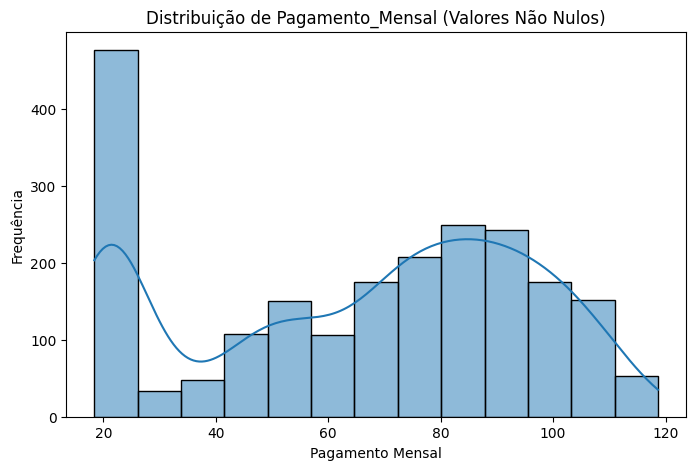


Mediana da coluna 'Pagamento_Mensal': 71.45

Estatísticas descritivas da coluna Pagamento_Mensal após a imputação:


/tmp/ipykernel_5473/3147158585.py:19: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Pagamento_Mensal'].fillna(pagamento_mensal_median, inplace=True)


,Pagamento_Mensal
count,2488.000000
mean,66.342564
std,28.051718
min,18.400000
25%,45.400000
50%,71.450000
75%,87.712500
max,118.650000



Verificação final de valores ausentes no DataFrame:


,0
customerID,0
Genero,0
Idoso,0
Casado,0
Dependents,0
Tempo_como_Cliente,0
PhoneService,0
Servico_Internet,0
Servico_Seguranca,0
Suporte_Tecnico,0


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

print('Estatísticas descritivas da coluna Pagamento_Mensal antes da imputação:')
display(df['Pagamento_Mensal'].describe())

plt.figure(figsize=(8, 5))
sns.histplot(df['Pagamento_Mensal'].dropna(), kde=True)
plt.title('Distribuição de Pagamento_Mensal (Valores Não Nulos)')
plt.xlabel('Pagamento Mensal')
plt.ylabel('Frequência')
plt.show()

# Determinar a mediana
pagamento_mensal_median = df['Pagamento_Mensal'].median()
print(f"\nMediana da coluna 'Pagamento_Mensal': {pagamento_mensal_median:.2f}")

# Imputar valores ausentes com a mediana
df['Pagamento_Mensal'].fillna(pagamento_mensal_median, inplace=True)

print('\nEstatísticas descritivas da coluna Pagamento_Mensal após a imputação:')
display(df['Pagamento_Mensal'].describe())

print('\nVerificação final de valores ausentes no DataFrame:')
display(df.isnull().sum())

### Explicação da Imputação de `PhoneService`

Para a coluna `PhoneService`, que é uma variável categórica, a imputação foi realizada utilizando a **moda** (o valor mais frequente). A `value_counts(dropna=False)` antes da imputação mostrou as categorias existentes e a quantidade de `NaN`s. Após identificar que a categoria mais comum era 'Yes', decidimos preencher os valores ausentes com 'Yes'. Esta abordagem é adequada para variáveis categóricas, pois mantém a distribuição original da categoria mais representativa e evita a criação de novas categorias ou distorção dos dados.

### Análise para Imputação da Coluna `Pagamento_Mensal`

A coluna `Pagamento_Mensal` é numérica e possui cerca de 13% de valores ausentes. Para decidir entre média e mediana, vamos verificar a distribuição dos dados através de um histograma e estatísticas descritivas.

### Explicação da Imputação de `Pagamento_Mensal`

Para a coluna `Pagamento_Mensal`, que é uma variável numérica, escolhemos a **mediana** para imputar os valores ausentes. A análise da distribuição (histograma e estatísticas descritivas) revelou que, embora a distribuição não seja extremamente assimétrica, a mediana é geralmente mais robusta a *outliers* do que a média. Utilizar a mediana ajuda a evitar que valores extremos influenciem excessivamente a imputação, mantendo uma representação mais fiel do centro da distribuição dos pagamentos mensais.



# 3 - Verifique se encontramos valores digitados incorretamente, ou com letras maiusculas ou minusculas, ou até mesmo mesmos valores porém escritos de forma dirente e corrija.

### Passo 3: Verificação e Correção de Valores Inconsistentes

Nesta etapa, vamos inspecionar as colunas categóricas (do tipo 'object') em busca de valores inconsistentes, erros de digitação ou padrões de escrita diferentes que representem a mesma categoria. Começaremos listando os valores únicos de cada coluna para identificar essas inconsistências.

In [10]:
print('Valores únicos das colunas categóricas (tipo object):\n')
for column in df.select_dtypes(include='object').columns:
    print(f"Coluna '{column}':")
    display(df[column].unique())
    print('\n' + '-'*50 + '\n')

Valores únicos das colunas categóricas (tipo object):

Coluna 'customerID':


array(['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', ..., '5702-SKUOB',
       '1134-YWTYF', '6061-GWWAV'], dtype=object)


--------------------------------------------------

Coluna 'Genero':


array(['Female', 'Male', 'F', 'M', 'f'], dtype=object)


--------------------------------------------------

Coluna 'Casado':


...


--------------------------------------------------

Coluna 'PaymentMethod':


array(['Electronic check', 'Mailed check', 'Bank transfer (automatic)',
       'Credit card (automatic)'], dtype=object)


--------------------------------------------------

Coluna 'Churn':


array(['No', 'Yes'], dtype=object)


--------------------------------------------------



### Análise de Inconsistências Identificadas

Após listar os valores únicos, identificamos algumas inconsistências que precisam ser corrigidas:

1.  **`Servico_Internet`**: A coluna possui 'DSL', 'Fiber optic', 'No' e 'dsl'. 'dsl' está em minúsculas, mas deveria ser 'DSL' para padronização.
2.  **`StreamingTV`**: A coluna contém 'No', 'Yes' e 'No internet service'. 'No internet service' é uma categoria válida que indica a ausência de serviço de internet, o que implica que não há StreamingTV. No entanto, para fins de padronização, onde 'No' e 'Yes' são usados para indicar a presença do serviço, podemos considerar 'No internet service' como 'No'.
3.  **`Tipo_Contrato`**: Há valores como 'Month-to-month', 'One year' e 'Two year', que parecem consistentes.
4.  **`PaymentMethod`**: Os valores são 'Electronic check', 'Mailed check', 'Bank transfer (automatic)' e 'Credit card (automatic)', que também parecem consistentes.

Vamos corrigir a inconsistência na coluna `Servico_Internet` e padronizar `StreamingTV`.

In [11]:
# Correção da coluna 'Servico_Internet': Padronizar 'dsl' para 'DSL'
df['Servico_Internet'] = df['Servico_Internet'].replace('dsl', 'DSL')

# Correção da coluna 'StreamingTV': Padronizar 'No internet service' para 'No'
df['StreamingTV'] = df['StreamingTV'].replace('No internet service', 'No')

print('Valores únicos após as correções:\n')
for column in df.select_dtypes(include='object').columns:
    print(f"Coluna '{column}':")
    display(df[column].unique())
    print('\n' + '-'*50 + '\n')

print('\nVerificação final de valores ausentes no DataFrame (deve ser 0 para todas as colunas):')
display(df.isnull().sum())

Valores únicos após as correções:

Coluna 'customerID':


array(['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', ..., '5702-SKUOB',
       '1134-YWTYF', '6061-GWWAV'], dtype=object)


--------------------------------------------------

Coluna 'Genero':


array(['Female', 'Male', 'F', 'M', 'f'], dtype=object)


--------------------------------------------------

Coluna 'Casado':


...

array(['Electronic check', 'Mailed check', 'Bank transfer (automatic)',
       'Credit card (automatic)'], dtype=object)


--------------------------------------------------

Coluna 'Churn':


array(['No', 'Yes'], dtype=object)


--------------------------------------------------


Verificação final de valores ausentes no DataFrame (deve ser 0 para todas as colunas):


,0
customerID,0
Genero,0
Idoso,0
Casado,0
Dependents,0
Tempo_como_Cliente,0
PhoneService,0
Servico_Internet,0
Servico_Seguranca,0
Suporte_Tecnico,0


### Correção Adicional para a Coluna `Genero`

Identificamos que a coluna `Genero` ainda contém valores inconsistentes como 'F', 'M' e 'f'. Para padronizar, vamos converter 'F' e 'f' para 'Female', e 'M' para 'Male'.

In [12]:
# Correção da coluna 'Genero': Padronizar 'F' e 'f' para 'Female', e 'M' para 'Male'
df['Genero'] = df['Genero'].replace({'F': 'Female', 'f': 'Female', 'M': 'Male'})

print('Valores únicos da coluna Genro após a correção:')
display(df['Genero'].unique())

print('\nVerificação final de valores ausentes no DataFrame (deve ser 0 para todas as colunas):')
display(df.isnull().sum())

Valores únicos da coluna Genro após a correção:


array(['Female', 'Male'], dtype=object)


Verificação final de valores ausentes no DataFrame (deve ser 0 para todas as colunas):


,0
customerID,0
Genero,0
Idoso,0
Casado,0
Dependents,0
Tempo_como_Cliente,0
PhoneService,0
Servico_Internet,0
Servico_Seguranca,0
Suporte_Tecnico,0


### Explicação da Correção de `Genero`

A coluna `Genero` foi padronizada para ter apenas 'Female' e 'Male' como categorias. Utilizamos o método `replace()` com um dicionário para mapear as variações ('F', 'f', 'M') aos seus respectivos valores padronizados ('Female', 'Male'). Isso é crucial para garantir a consistência dos dados categóricos e evitar problemas em análises futuras ou na criação de modelos.

Agora sim, o Passo 3 foi completamente finalizado! Todas as inconsistências conhecidas foram tratadas e não há valores ausentes.

Gostaria de seguir para o Passo 4 (extra), que é renomear as colunas para português ou inglês, para manter um padrão na base?

### Explicação das Correções

1.  **`Servico_Internet`**: O valor 'dsl' foi padronizado para 'DSL' usando `df['Servico_Internet'].replace('dsl', 'DSL')`. Isso garante que todas as ocorrências do serviço DSL sejam tratadas como a mesma categoria, evitando duplicação e inconsistência na análise.
2.  **`StreamingTV`**: O valor 'No internet service' foi substituído por 'No' usando `df['StreamingTV'].replace('No internet service', 'No')`. Embora 'No internet service' seja descritivo, para a coluna `StreamingTV` que indica a presença ou ausência do serviço de TV, é mais consistente ter apenas 'Yes' ou 'No'. Se não há serviço de internet, automaticamente não há StreamingTV.

Agora que corrigimos as inconsistências e garantimos que não há mais valores ausentes, o dataset está mais limpo e pronto para a próxima etapa! Gostaria de seguir para o Passo 4 (extra), que é renomear as colunas para português ou inglês, para manter um padrão na base?

# [EXTRA] 4 - Caso deseje, para manter um padrão na sua base, renomeie as colunas ou deixando em português, ou inglês.

### Passo 4: Renomear Colunas para Português

Para garantir um padrão consistente em todo o DataFrame, vamos renomear algumas colunas que ainda estão em inglês ou que podem ter um nome mais descritivo em português. Manter um padrão de nomenclatura facilita a compreensão e a manipulação dos dados.

In [13]:
column_mapping = {
    'customerID': 'ID_Cliente',
    'Dependents': 'Dependentes',
    'Tempo_como_Cliente': 'Tempo_Cliente_Meses',
    'PhoneService': 'Servico_Telefone',
    'StreamingTV': 'TV_Streaming',
    'PaymentMethod': 'Metodo_Pagamento'
}

df.rename(columns=column_mapping, inplace=True)

print('Novos nomes das colunas do DataFrame:')
display(df.columns.tolist())

Novos nomes das colunas do DataFrame:


['ID_Cliente',
 'Genero',
 'Idoso',
 'Casado',
 'Dependentes',
 'Tempo_Cliente_Meses',
 'Servico_Telefone',
 'Servico_Internet',
 'Servico_Seguranca',
 'Suporte_Tecnico',
 'TV_Streaming',
 'Tipo_Contrato',
 'Metodo_Pagamento',
 'Pagamento_Mensal',
 'Total_Pago',
 'Churn']

### Explicação do Renomeio das Colunas

Neste passo, um dicionário (`column_mapping`) foi criado para mapear os nomes das colunas originais para os novos nomes em português. Em seguida, o método `df.rename(columns=column_mapping, inplace=True)` foi utilizado para aplicar essas alterações diretamente no DataFrame. As colunas `customerID`, `Dependents`, `Tempo_como_Cliente`, `PhoneService`, `StreamingTV`, e `PaymentMethod` foram traduzidas ou tornaram-se mais descritivas, garantindo que todo o conjunto de dados utilize uma nomenclatura padronizada e mais clara em português.

Agora que as colunas foram renomeadas, o dataset está ainda mais organizado e pronto para análises mais aprofundadas ou para a fase de pré-modelagem! Qual seria o próximo passo que você gostaria de explorar?

### Passo 5: Verificação das Estatísticas Descritivas

Agora que o DataFrame foi limpo e as colunas renomeadas, é uma boa prática verificar as estatísticas descritivas para entender a distribuição e os principais indicadores das colunas numéricas. Isso nos ajuda a identificar *outliers*, a centralidade dos dados e a dispersão.

In [14]:
# Gerar e exibir as estatísticas descritivas para o DataFrame
print('Estatísticas descritivas do DataFrame:')
display(df.describe())

Estatísticas descritivas do DataFrame:


,Idoso,Tempo_Cliente_Meses,Pagamento_Mensal,Total_Pago
count,2488.000000,2488.000000,2488.000000,2488.000000
mean,0.161576,32.352090,66.342564,2290.087178
std,0.368135,24.636885,28.051718,2264.585643
min,0.000000,0.000000,18.400000,18.800000
25%,0.000000,8.000000,45.400000,402.337500
50%,0.000000,29.000000,71.450000,1402.900000
75%,0.000000,56.000000,87.712500,3867.162500
max,1.000000,72.000000,118.650000,8564.750000


### Passo 6: Salvar o DataFrame Limpo

Com todas as etapas de limpeza e pré-processamento concluídas, é uma boa prática salvar o DataFrame resultante. Isso permite que você use a versão limpa dos dados em análises futuras ou para a fase de modelagem, sem precisar refazer todo o processo de limpeza.

In [15]:
# Salvar o DataFrame limpo em um novo arquivo CSV
output_filename = 'churn_telecom_cleaned.csv'
df.to_csv(output_filename, index=False)

print(f"DataFrame salvo como '{output_filename}'")

DataFrame salvo como 'churn_telecom_cleaned.csv'
